# 04: Visualizations, 3D Geometry & Multiple Linear Regression
**Syllabus Coverage:** Unit I (Overfitting Curves) & Unit VI (Visualizations & Regression)

### Objectives:
1. Render 2D visualizations: Correlation heatmap, distribution histograms, dispatch curves.
2. Construct Matplotlib 3D Scatter Plot ($X = \text{Load}$, $Y = \text{Temp}$, $Z = \text{Carbon Intensity}$).
3. Demonstrate overfitting control via train vs. validation loss curve tracking across polynomial degrees.
4. Train and benchmark Simple Linear Regression (SLR) vs. Multiple Linear Regression (MLR) with $R^2$, RMSE, and MAE.
5. Analyze MLR residuals and evaluate load-shift arbitrage savings in INR (₹).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import load_clean_data
from src.models import train_evaluate_mlr, compute_overfitting_curve
from src.optimizer import optimize_load_shift, JOB_PRESETS

sns.set_theme(style='darkgrid')
print('Imports successful.')

Imports successful.


## 1. Correlation Heatmap & 2D Visualizations (Unit VI)
Examining cross-correlations between weather parameters, grid load, generation fleet, and emissions.

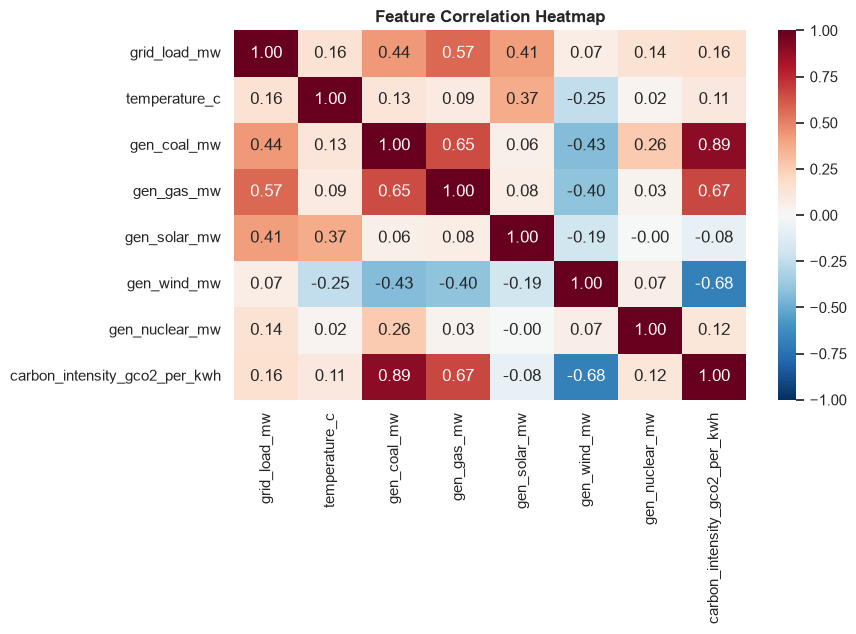

In [2]:
df = load_clean_data('../data/processed/grid_telemetry_clean.csv')
corr_cols = [
    'grid_load_mw', 'temperature_c', 'gen_coal_mw', 'gen_gas_mw',
    'gen_solar_mw', 'gen_wind_mw', 'gen_nuclear_mw', 'carbon_intensity_gco2_per_kwh'
]
plt.figure(figsize=(9, 6.5))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='RdBu_r', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. 3D Spatial Geometry Scatter Plot (Unit VI)
Visualizing the non-linear relationship where high temperature induces peak cooling load, forcing marginal gas peaker dispatch that spikes carbon emissions:
$$X = \text{Grid Load (MW)}, \quad Y = \text{Ambient Temp (°C)}, \quad Z = \text{Carbon Intensity (gCO}_2/\text{kWh})$$

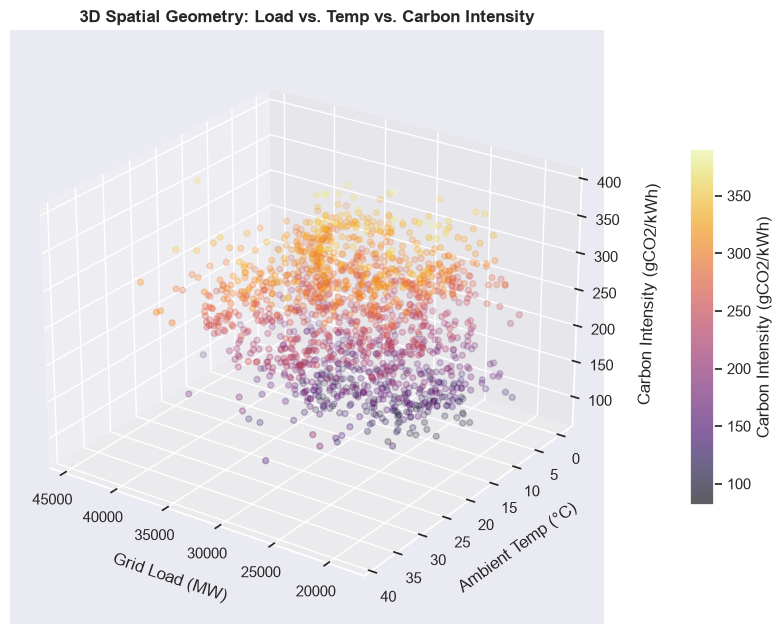

In [3]:
sampled_df = df.sample(n=1500, random_state=42)
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection='3d')

p3d = ax.scatter(
    sampled_df['grid_load_mw'],
    sampled_df['temperature_c'],
    sampled_df['carbon_intensity_gco2_per_kwh'],
    c=sampled_df['carbon_intensity_gco2_per_kwh'],
    cmap='inferno',
    s=18,
    alpha=0.6,
)
ax.view_init(elev=25, azim=125)
ax.set_xlabel('Grid Load (MW)', labelpad=10)
ax.set_ylabel('Ambient Temp (°C)', labelpad=10)
ax.set_zlabel('Carbon Intensity (gCO2/kWh)', labelpad=10)
ax.set_title('3D Spatial Geometry: Load vs. Temp vs. Carbon Intensity', fontsize=12, fontweight='bold')
cbar = fig.colorbar(p3d, shrink=0.6, aspect=15, pad=0.1)
cbar.set_label('Carbon Intensity (gCO2/kWh)')
plt.tight_layout()
plt.show()

## 3. Overfitting Control: Train vs. Validation Loss Curves (Unit I)
Tracking loss as polynomial model complexity increases from degree 1 to 5, demonstrating bias-variance tradeoff.

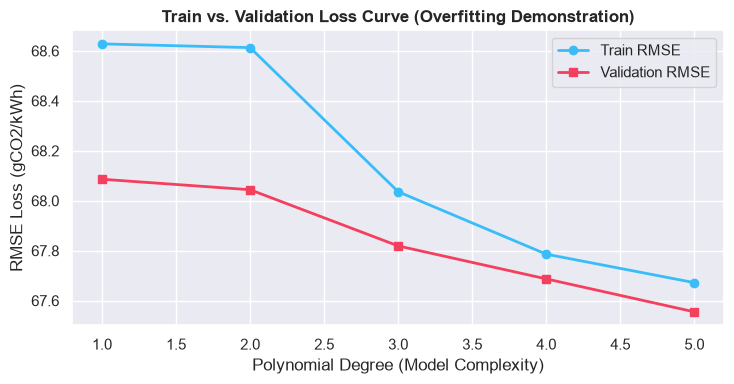

In [4]:
curve = compute_overfitting_curve(df, max_degree=5)
plt.figure(figsize=(7.5, 4))
plt.plot(curve['degrees'], curve['train_rmse'], 'o-', color='#38BDF8', lw=2, label='Train RMSE')
plt.plot(curve['degrees'], curve['val_rmse'], 's-', color='#F43F5E', lw=2, label='Validation RMSE')
plt.title('Train vs. Validation Loss Curve (Overfitting Demonstration)', fontsize=12, fontweight='bold')
plt.xlabel('Polynomial Degree (Model Complexity)')
plt.ylabel('RMSE Loss (gCO2/kWh)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Simple vs. Multiple Linear Regression (Unit VI)
Evaluating:
$$\text{SLR}: \quad \hat{CI}_t = \beta_0 + \beta_1(\text{Load}_t)$$
$$\text{MLR}: \quad \hat{CI}_t = \beta_0 + \beta_1(\text{Load}_t) + \beta_2(\text{Temp}_t) + \beta_3(\text{Solar}_t) + \beta_4(\text{Wind}_t) + \beta_5(h_{\sin}) + \beta_6(h_{\cos})$$

--- Performance Comparison ---
Simple Linear Regression:   R2 = 0.0313, RMSE = 68.36, MAE = 57.77
Multiple Linear Regression: R2 = 0.6407, RMSE = 41.63, MAE = 33.56
RMSE Error Reduction: +39.1%

MLR Feature Coefficients:
  grid_load_mw       -> +0.0056
  temperature_c      -> -0.0288
  gen_solar_mw       -> -0.0165
  gen_wind_mw        -> -0.0165
  hour_sin           -> -0.4958
  hour_cos           -> -0.4629
  Intercept:          +189.60


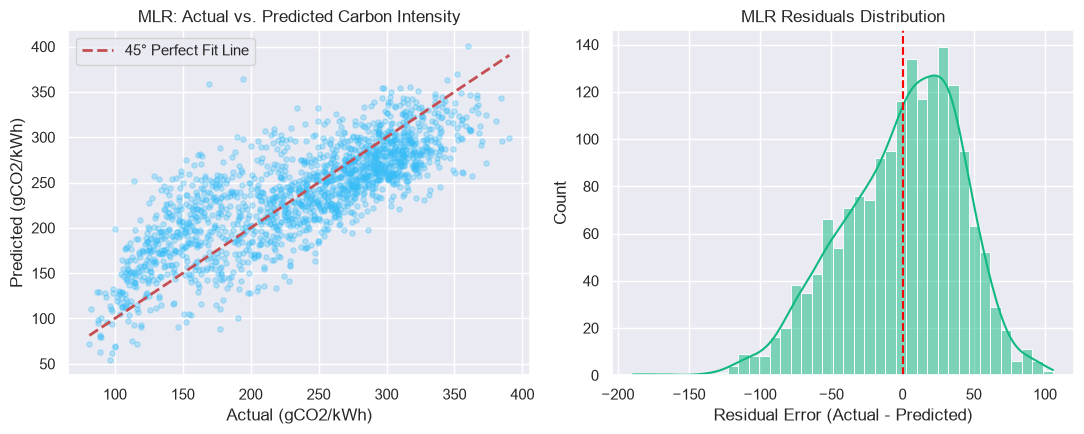

In [5]:
mlr_res = train_evaluate_mlr(df)
print('--- Performance Comparison ---')
print(f"Simple Linear Regression:   R2 = {mlr_res['metrics_slr']['r2']:.4f}, RMSE = {mlr_res['metrics_slr']['rmse']:.2f}, MAE = {mlr_res['metrics_slr']['mae']:.2f}")
print(f"Multiple Linear Regression: R2 = {mlr_res['metrics_mlr']['r2']:.4f}, RMSE = {mlr_res['metrics_mlr']['rmse']:.2f}, MAE = {mlr_res['metrics_mlr']['mae']:.2f}")
print(f"RMSE Error Reduction: +{mlr_res['improvement_pct']}%")

print('\nMLR Feature Coefficients:')
for feat, coef in mlr_res['coefficients'].items():
    print(f"  {feat:18s} -> {coef:+.4f}")
print(f"  Intercept:          {mlr_res['intercept']:+.2f}")

# Actual vs Predicted & Residuals
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(mlr_res['y_true_test'], mlr_res['y_pred_test'], alpha=0.3, color='#38BDF8', s=14)
m_val = [mlr_res['y_true_test'].min(), mlr_res['y_true_test'].max()]
axes[0].plot(m_val, m_val, 'r--', lw=2, label='45° Perfect Fit Line')
axes[0].set_title('MLR: Actual vs. Predicted Carbon Intensity')
axes[0].set_xlabel('Actual (gCO2/kWh)')
axes[0].set_ylabel('Predicted (gCO2/kWh)')
axes[0].legend()

sns.histplot(mlr_res['residuals'], kde=True, color='#10B981', ax=axes[1], bins=40)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('MLR Residuals Distribution')
axes[1].set_xlabel('Residual Error (Actual - Predicted)')
plt.tight_layout()
plt.show()

## 5. Load-Shift Arbitrage Engine Simulation in INR (₹)
Shifting a 250 kW AI batch training job from peak hours to clean, low-tariff off-peak windows.

In [6]:
job = JOB_PRESETS['AI Cluster Batch Compute']
opt = optimize_load_shift(
    df, start_idx=0, horizon_hours=24, power_kw=job['power_kw'],
    duration_hours=job['duration_hours'], baseline_start_hour=job['default_baseline_start'],
    lambda_weight=0.5
)
baseline_cost = opt.get('baseline_cost_inr', opt.get('baseline_cost_usd'))
optimal_cost = opt.get('optimal_cost_inr', opt.get('optimal_cost_usd'))
cost_saved = opt.get('cost_saved_inr', opt.get('cost_saved_usd'))

print(f"Baseline Start: Hour {opt['baseline_start_clock_hour']:02d}:00 | Cost: ₹{baseline_cost:,.2f} | Carbon: {opt['baseline_carbon_kg']:.1f} kg CO2")
print(f"Optimal Start:  Hour {opt['optimal_start_clock_hour']:02d}:00 | Cost: ₹{optimal_cost:,.2f} | Carbon: {opt['optimal_carbon_kg']:.1f} kg CO2")
print(f"Financial Savings: ₹{cost_saved:,.2f} ({opt['cost_saved_pct']:.1f}% reduction)")
print(f"Carbon Abated:     {opt['carbon_saved_kg']:.1f} kg CO2 ({opt['carbon_saved_pct']:.1f}% reduction)")

Baseline Start: Hour 14:00 | Cost: ₹18,000.00 | Carbon: 133.2 kg CO2
Optimal Start:  Hour 00:00 | Cost: ₹9,750.00 | Carbon: 189.5 kg CO2
Financial Savings: ₹8,250.00 (45.8% reduction)
Carbon Abated:     -56.3 kg CO2 (-42.2% reduction)
